# MTAOS closed-loop step for one visit (v1)

**Author:** Aaron Roodman (with Claude)  
**Date Created:** 2026-11-09  
**Last Modified:** 2026-11-09  
**Status:** In Progress  
**Keywords:** MTAOS, OFC, PID, Tweak, Trim, corner wavefront sensor, v-modes  

## Description

For one visit, collect from the EFD and ConsDB everything the MTAOS closed loop did:
the corner Zernike deviation sent to the Optical Feedback Controller (OFC), the
Wavefront Estimation Pipeline (WEP) log lines, the optical state (22 DOF and 12
v-modes), the PID input and output, the Tweak (`visitDoF`) and Trim (`aggregatedDoF`),
and when each correction was issued. It then reproduces the state estimate and the PID
step with the summit versions of `ts_ofc` and `ts_config_mttcs`.

Two OFC steps matter for a visit V, and both are shown:
1. the step **in effect** during V: computed from an earlier image, issued before V opened;
2. the step **computed from** V's own wavefront, applied to a later visit.

**Output:** one PDF and CSV tables in the run directory (`run.path`).

**Based on:** `olr/aos_dof_audit/code/aos_dof_audit.py` (per-night version);
`ts_ofc` `OFC.calculate_corrections` and `BaseController.calculate_pid_step`.

## Change Log

| Date | Author | Description |
|------|--------|-------------|
| 2026-11-09 | Aaron Roodman | Initial version: 20261108 seq 468 |

## Table of Contents

1. [Parameters](#params)
2. [Setup & Imports](#setup)
3. [Data Access](#data)
4. [OFC steps in the window](#steps)
5. [The two steps for this visit](#audit)
6. [Summary table](#summary)
7. [Figures](#figures)

<a id='params'></a>
## Parameters

In [1]:
DAY_OBS = 20261108
SEQ_NUM = 468
SEQ_BEFORE = 8          # exposures before SEQ_NUM to fetch, enough to find the step in effect
SEQ_AFTER = 3           # exposures after, enough to find where SEQ_NUM's own step applied
PAD_S = 120             # EFD window padding, s

# Local clones, only read: the summit tags are exported from them with git archive.
TS_OFC_REPO = "/sdf/group/rubin/u/roodman/LSST/packages/ts_ofc"
TS_CONFIG_REPO = "/sdf/group/rubin/u/roodman/LSST/packages/ts_config_mttcs"

from rubinwork.common import study_run
run = study_run("aos/aos_byvisit", f"visit_{DAY_OBS}_{SEQ_NUM:05d}")
print(run.path)

/sdf/group/rubin/u/roodman/LSST/rubin-work/studies/aos/aos_byvisit/20261109_visit_20261108_00468


<a id='setup'></a>
## Setup & Imports

In [2]:
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from astropy.time import TimeDelta

from rubinwork.common.utils import repo_root, setup_plotting
from rubinwork.common.telemetry_clients import make_efd_client, make_consdb_client

sys.path.insert(0, str(repo_root() / "aos" / "aos_byvisit" / "code"))
import byvisit as bv

warnings.filterwarnings("ignore", category=FutureWarning)
setup_plotting()
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)

# Summit ts_ofc must be imported before anything else imports lsst.ts.ofc.
ofc_python, ofc_config = bv.export_summit_sources(run.path.parent / "summit_src",
                                                  TS_OFC_REPO, TS_CONFIG_REPO)
bv.use_summit_ts_ofc(ofc_python)
print(ofc_python, ofc_config, sep="\n")

/sdf/group/rubin/u/roodman/LSST/rubin-work/studies/aos/aos_byvisit/summit_src/ts_ofc_v4.8.1/python
/sdf/group/rubin/u/roodman/LSST/rubin-work/studies/aos/aos_byvisit/summit_src/ts_config_mttcs_v0.22.12/MTAOS/v13/ofc


<a id='data'></a>
## Data Access

In [3]:
efd = make_efd_client()
cdb = make_consdb_client()

ex = bv.exposures(cdb, DAY_OBS, SEQ_NUM - SEQ_BEFORE, SEQ_NUM + SEQ_AFTER)
ev = await bv.fetch_window(efd, ex.t0_utc.iloc[0] - TimeDelta(PAD_S, format="sec"),
                           ex.t1_utc.iloc[-1] + TimeDelta(PAD_S, format="sec"))
ex = bv.exposure_pointing(ev, ex)
versions = await bv.software_versions(efd, ex.t0_utc.loc[SEQ_NUM])
print(versions)
if f"ts_ofc={bv.TS_OFC_TAG}" not in versions.get("subsystems", "") \
        or bv.TS_CONFIG_MTTCS_TAG not in versions.get("config_version", ""):
    print("WARNING: summit versions differ from the exported tags; set bv.TS_OFC_TAG / "
          "bv.TS_CONFIG_MTTCS_TAG and rerun")
ex[["obs_start", "img_type", "observation_reason", "band", "exp_time", "el_deg", "rot_deg"]]

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.


        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


{'csc': 'v0.30.0-alpha.5', 'subsystems': 'ts_ofc=v4.8.1,ts_wep=?,lsst_distrib=current:w_2026_22', 'config_schema': 'v13', 'config_url': 'file:///net/obs-env/auto_base_packages/ts_config_mttcs/MTAOS/v13', 'config_version': 'tags/v0.22.12-0-g068de03'}


,obs_start,img_type,observation_reason,band,exp_time,el_deg,rot_deg
seq_num,,,,,,,
460,2026-11-09T07:10:16.660000,science,pairs_ur_33.0,u,38.0,60.542732,5.335558
461,2026-11-09T07:11:08.654000,science,pairs_ur_33.0,u,38.0,62.344772,7.819388
462,2026-11-09T07:11:59.012000,science,pairs_ur_33.0,u,38.0,62.040468,10.002136
463,2026-11-09T07:12:49.710000,science,pairs_ur_33.0,u,38.0,63.938952,10.904843
464,2026-11-09T07:13:36.381000,science,pairs_ur_33.0,u,38.0,65.212117,13.701130
465,2026-11-09T07:14:22.910000,science,pairs_ur_33.0,u,38.0,67.184474,14.717827
466,2026-11-09T07:15:11.077000,science,pairs_ur_33.0,u,38.0,68.368180,18.323244
467,2026-11-09T07:15:58.456000,science,pairs_ur_33.0,u,38.0,69.188531,21.886200
468,2026-11-09T07:16:54.131000,science,pairs_ur_33.0,u,38.0,71.488293,24.369076


<a id='steps'></a>
## OFC steps in the window

One row per `degreeOfFreedom` event. `source_seq` is the image whose wavefront fed the
step; `applied_to_seq` is the first exposure that opened after `command_issueCorrection`.
Visits with no row were skipped by MTAOS (taken before the last correction landed, or
too far in rotator angle or elevation from the current pointing).

In [4]:
steps = bv.ofc_steps(ev, ex)
se = bv.summit_state_estimator(ofc_config)
steps[["visit_id", "t_dof", "t_issued", "applied_to_seq"]]

,visit_id,t_dof,t_issued,applied_to_seq
source_seq,,,,
456,2026110800456,2026-11-09 07:08:05.601382+00:00,2026-11-09 07:08:44.332305+00:00,460.0
459,2026110800459,2026-11-09 07:10:25.625016+00:00,2026-11-09 07:10:26.794042+00:00,461.0
461,2026110800461,2026-11-09 07:12:06.055954+00:00,2026-11-09 07:12:08.443198+00:00,463.0
463,2026110800463,2026-11-09 07:13:47.818366+00:00,2026-11-09 07:14:26.110230+00:00,466.0
466,2026110800466,2026-11-09 07:16:02.609832+00:00,2026-11-09 07:16:09.410486+00:00,468.0
468,2026110800468,2026-11-09 07:17:47.588835+00:00,2026-11-09 07:17:55.607465+00:00,470.0
470,2026110800470,2026-11-09 07:19:34.194724+00:00,2026-11-09 07:19:43.843155+00:00,NaN


In [5]:
# MTAOS log lines naming a skipped image
lm = ev["logevent_logMessage"]
skips = lm[lm.message.str.contains("Skipping")].message.str.slice(0, 220)
skips.to_frame()

,message
2026-11-09 07:08:44.810578+00:00,Exposure MC_O_20261108_000457 started 88.14s b...
2026-11-09 07:08:53.771016+00:00,Exposure MC_O_20261108_000458 started 40.57s b...
2026-11-09 07:10:28.937469+00:00,Exposure MC_O_20261108_000460 started 48.12s b...
2026-11-09 07:12:11.992680+00:00,Exposure MC_O_20261108_000462 started 46.83s b...
2026-11-09 07:14:26.587617+00:00,Exposure MC_O_20261108_000464 started 87.20s b...
2026-11-09 07:14:36.168195+00:00,Exposure MC_O_20261108_000465 started 40.67s b...
2026-11-09 07:16:10.250305+00:00,Exposure MC_O_20261108_000467 started 48.78s b...
2026-11-09 07:17:56.406328+00:00,Exposure MC_O_20261108_000469 started 50.18s b...
2026-11-09 07:19:45.167554+00:00,Exposure MC_O_20261108_000471 started 54.92s b...
2026-11-09 07:20:38.681586+00:00,"Current rotator position: 36.5, current elevat..."


<a id='audit'></a>
## The two steps for this visit

For each step: WEP log, corner Zernikes, the reproduced state and v-modes, and the
22-DOF table. Columns of the DOF table (units in `unit`):

- `state (log, -error)`: optical state from the logged PID error (setpoint 0);
- `state (repro)`: `StateEstimator.dof_state` on the EFD wavefront;
- `integral clipped (log)`: the integral term after MTAOS clipping;
- `tweak (EFD visitDoF)` and `tweak (repro)` = -kp x error;
- `tweak if P used clipped` = -kp x clipped integral: what the clip would have allowed if
  it acted on the proportional term;
- `trim before`, `trim after`, `trim change` from `aggregatedDoF`.

In [6]:
def audit(src):
    """Everything for the OFC step whose source image is seq ``src``."""
    s = steps.loc[src]
    earlier = steps[steps.t_dof < s.t_dof]
    prev = earlier.iloc[-1] if len(earlier) else None
    wfe = bv.wavefront(ev, s.visit_id)
    pid = bv.pid_log(ev, s.t_dof)
    rep = bv.reproduce_step(se, wfe, ex.rot_deg.loc[src], ex.band.loc[src], s.kp, s.ki, s.kd)
    table = bv.step_table(s, prev, pid, rep)
    rel = np.abs(rep["error"] - pid["error"]).max() / np.abs(pid["error"]).max()
    return dict(src=src, step=s, prev=prev, wfe=wfe, pid=pid, rep=rep, table=table,
                wep=bv.wep_log(ev, src, s.t_dof, DAY_OBS),
                consdb=bv.consdb_zernikes(cdb, s.visit_id), repro_rel=rel)


in_effect = steps.index[steps.applied_to_seq == SEQ_NUM]
cases = {}
if len(in_effect):
    cases["in effect"] = audit(int(in_effect[-1]))
else:
    print(f"no OFC step was applied just before seq {SEQ_NUM}")
if SEQ_NUM in steps.index:
    cases["from this visit"] = audit(SEQ_NUM)
else:
    print(f"MTAOS ran no OFC step on seq {SEQ_NUM}")
{k: v["src"] for k, v in cases.items()}

{'in effect': 466, 'from this visit': 468}

In [7]:
for name, a in cases.items():
    s = a["step"]
    print(f"===== step {name}: source seq {a['src']}, issued {s.t_issued}, applied to seq {s.applied_to_seq}")
    w = a["wep"]
    print(f"WEP tables found {w['tables_found']} of {w['tables_total']}; MTAOS claims "
          f"{w['measurements_claimed']} measurements; finite corners "
          f"{len(a['rep']['corners_used'])} {a['rep']['corners_used']}")
    print(f"rotator {ex.rot_deg.loc[a['src']]:.3f} deg, elevation {ex.el_deg.loc[a['src']]:.3f} deg")
    print(f"reproduction: max|repro - logged| / max|logged| PID error = {a['repro_rel']:.2e} (dimensionless)")
    print("donut sizes (px) and defocus offsets (um) from the MTAOS log:")
    display(w["donuts"])

===== step in effect: source seq 466, issued 2026-11-09 07:16:09.410486+00:00, applied to seq 468.0
WEP tables found 4 of 4; MTAOS claims 4 measurements; finite corners 2 [199, 203]
rotator 18.323 deg, elevation 68.368 deg
reproduction: max|repro - logged| / max|logged| PID error = 7.97e-04 (dimensionless)
donut sizes (px) and defocus offsets (um) from the MTAOS log:


,intra_px,extra_px,defocus_offset_um
detector,,,
191,224.0,80.0,3554.18
195,36.0,192.0,2832.15
199,64.0,64.0,-55.95
203,56.0,68.0,34.30


===== step from this visit: source seq 468, issued 2026-11-09 07:17:55.607465+00:00, applied to seq 470.0
WEP tables found 4 of 4; MTAOS claims 4 measurements; finite corners 4 [191, 195, 199, 203]
rotator 24.369 deg, elevation 71.488 deg
reproduction: max|repro - logged| / max|logged| PID error = 9.54e-04 (dimensionless)
donut sizes (px) and defocus offsets (um) from the MTAOS log:


,intra_px,extra_px,defocus_offset_um
detector,,,
191,80.0,34.0,305.06
195,6.5,40.0,-597.47
199,60.0,64.0,-55.95
203,60.0,32.0,-146.20


In [8]:
for name, a in cases.items():
    print(f"===== step {name}: EFD wavefrontError deviation, um of wavefront, CCS")
    display(a["wfe"].round(3))
    print(f"ConsDB ccdvisit1_quicklook z4..z28, um (OPD or deviation, frame undocumented)")
    display(a["consdb"].round(3))

===== step in effect: EFD wavefrontError deviation, um of wavefront, CCS


,Z4,Z5,Z6,Z7,Z8,Z9,Z10,Z11,Z12,Z13,Z14,Z15,Z16,Z17,Z18,Z19,Z22,Z23,Z24,Z25,Z26
191,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
195,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
199,-0.142,0.120,-0.103,0.029,-0.049,0.043,-0.066,-0.001,-0.019,0.146,-0.022,-0.201,0.015,0.092,0.009,0.006,0.045,-0.027,0.013,0.027,0.018
203,-0.214,-0.356,0.267,0.217,0.163,0.148,-0.165,0.113,-0.363,0.122,0.005,-0.037,0.032,0.137,0.011,-0.021,0.050,0.014,0.101,0.036,-0.063


ConsDB ccdvisit1_quicklook z4..z28, um (OPD or deviation, frame undocumented)


,Z4,Z5,Z6,Z7,Z8,Z9,Z10,Z11,Z12,Z13,Z14,Z15,Z16,Z17,Z18,Z19,Z20,Z21,Z22,Z23,Z24,Z25,Z26,Z27,Z28
det,,,,,,,,,,,,,,,,,,,,,,,,,
191,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
195,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
199,-0.154,0.242,-0.174,0.053,0.146,-0.054,-0.060,-0.052,-0.077,0.049,0.199,-0.091,-0.010,0.074,0.011,0.004,None,None,0.060,-0.010,0.043,0.032,-0.061,None,None
203,-0.249,-0.000,0.243,0.311,0.179,-0.109,-0.234,0.066,-0.328,-0.125,0.073,-0.033,-0.026,0.212,0.047,-0.039,None,None,0.071,0.073,0.048,-0.012,-0.071,None,None


===== step from this visit: EFD wavefrontError deviation, um of wavefront, CCS


,Z4,Z5,Z6,Z7,Z8,Z9,Z10,Z11,Z12,Z13,Z14,Z15,Z16,Z17,Z18,Z19,Z22,Z23,Z24,Z25,Z26
191,-7.994,0.024,0.501,0.004,-1.824,-0.125,0.593,0.025,-0.220,0.031,-0.167,-0.255,0.282,0.122,0.028,0.024,0.041,-0.006,0.070,-0.068,0.037
195,-9.215,-0.092,-1.471,1.510,0.069,0.336,0.587,-0.193,0.073,0.094,-0.014,-0.140,-0.137,-0.234,-0.102,-0.105,0.051,-0.032,-0.119,-0.053,0.093
199,0.370,0.014,-0.554,0.022,0.091,0.396,-0.011,-0.031,0.024,0.143,0.034,-0.440,-0.056,0.051,0.079,-0.048,0.031,-0.033,-0.006,0.076,0.024
203,-0.744,-0.152,-0.091,-0.306,0.017,0.382,0.162,-0.003,-0.185,0.123,0.102,-0.297,-0.024,0.125,0.088,0.009,0.020,-0.003,0.048,0.063,-0.022


ConsDB ccdvisit1_quicklook z4..z28, um (OPD or deviation, frame undocumented)


,Z4,Z5,Z6,Z7,Z8,Z9,Z10,Z11,Z12,Z13,Z14,Z15,Z16,Z17,Z18,Z19,Z20,Z21,Z22,Z23,Z24,Z25,Z26,Z27,Z28
det,,,,,,,,,,,,,,,,,,,,,,,,,
191,-8.062,0.243,0.103,-1.017,-1.713,0.519,0.289,-0.032,-0.117,-0.163,0.303,-0.069,0.219,0.230,-0.020,0.026,None,None,0.071,0.043,0.040,0.057,0.002,None,None
195,-9.207,-1.069,-0.802,1.357,-0.749,0.691,-0.248,-0.279,-0.053,0.112,0.190,0.027,-0.056,-0.261,0.073,-0.119,None,None,0.075,-0.118,-0.038,0.092,-0.024,None,None
199,0.347,-0.277,-0.437,0.136,0.233,0.103,-0.366,-0.077,-0.045,0.076,0.452,0.102,-0.058,0.006,0.082,0.055,None,None,0.049,-0.021,0.035,-0.004,-0.117,None,None
203,-0.818,-0.097,-0.099,-0.164,0.217,0.214,-0.273,-0.057,-0.190,-0.066,0.337,0.153,-0.102,0.169,0.050,0.060,None,None,0.049,0.029,0.016,-0.015,-0.092,None,None


In [9]:
for name, a in cases.items():
    print(f"===== step {name} (source seq {a['src']}): 22-DOF table")
    display(a["table"].round(4))

===== step in effect (source seq 466): 22-DOF table


,unit,"state (log, -error)",state (repro),integral clipped (log),kp,tweak (EFD visitDoF),tweak (repro),tweak if P used clipped,trim before,trim after,trim change
M2 dz,um,251.7680,251.7901,-251.7680,0.3,75.5304,75.5370,75.5304,-525.5267,-449.9963,75.5304
M2 dx,um,-768.6676,-768.8976,100.0000,0.3,-230.6003,-230.6693,-30.0000,-33.1625,-263.7628,-230.6003
M2 dy,um,-169.6326,-168.9787,100.0000,0.3,-50.8898,-50.6936,-30.0000,320.2334,269.3436,-50.8898
M2 rx,deg,0.0005,0.0005,-0.0005,0.3,0.0001,0.0001,0.0001,0.0012,0.0014,0.0001
M2 ry,deg,-0.0050,-0.0050,0.0050,0.3,-0.0015,-0.0015,-0.0015,-0.0022,-0.0037,-0.0015
Cam dz,um,-1152.5048,-1152.6096,500.0000,0.3,-345.7514,-345.7829,-150.0000,-169.8983,-515.6498,-345.7514
Cam dx,um,-1379.5515,-1380.0525,100.0000,0.3,-413.8654,-414.0157,-30.0000,-510.7521,-924.6175,-413.8654
Cam dy,um,-340.0701,-338.9706,100.0000,0.3,-102.0210,-101.6912,-30.0000,-2758.5860,-2860.6070,-102.0210
Cam rx,deg,0.0663,0.0661,-0.0100,0.3,0.0199,0.0198,0.0030,-0.0096,0.0103,0.0199
Cam ry,deg,-0.2030,-0.2031,0.0100,0.3,-0.0609,-0.0609,-0.0030,0.0008,-0.0601,-0.0609


===== step from this visit (source seq 468): 22-DOF table


,unit,"state (log, -error)",state (repro),integral clipped (log),kp,tweak (EFD visitDoF),tweak (repro),tweak if P used clipped,trim before,trim after,trim change
M2 dz,um,1061.2730,1061.2522,-500.0000,0.3,318.3819,318.3757,150.0000,-449.9963,-131.6144,318.3819
M2 dx,um,-144.3426,-144.2493,100.0000,0.3,-43.3028,-43.2748,-30.0000,-263.7628,-307.0656,-43.3028
M2 dy,um,102.8866,102.9541,-100.0000,0.3,30.8660,30.8862,30.0000,269.3436,300.2096,30.8660
M2 rx,deg,0.0007,0.0007,-0.0007,0.3,0.0002,0.0002,0.0002,0.0014,0.0016,0.0002
M2 ry,deg,0.0036,0.0036,-0.0036,0.3,0.0011,0.0011,0.0011,-0.0037,-0.0026,0.0011
Cam dz,um,-790.9221,-790.9012,500.0000,0.3,-237.2766,-237.2703,-150.0000,-515.6498,-752.9264,-237.2766
Cam dx,um,2952.4452,2951.8322,-100.0000,0.3,885.7335,885.5496,30.0000,-924.6175,-38.8840,885.7335
Cam dy,um,-697.3381,-700.1535,100.0000,0.3,-209.2014,-210.0461,-30.0000,-2860.6070,-3069.8084,-209.2014
Cam rx,deg,-0.0192,-0.0191,0.0100,0.3,-0.0057,-0.0057,-0.0030,0.0103,0.0045,-0.0057
Cam ry,deg,0.0559,0.0560,-0.0100,0.3,0.0168,0.0168,0.0030,-0.0601,-0.0434,0.0168


In [10]:
vm = pd.DataFrame({f"{n} (seq {a['src']})": a["rep"]["vmodes"][:bv.N_VMODES]
                   for n, a in cases.items()},
                  index=[f"v{i}" for i in range(1, bv.N_VMODES + 1)])
print("optical state in v-modes, normalized amplitude (dimensionless), summit basis")
vm.round(4)

optical state in v-modes, normalized amplitude (dimensionless), summit basis


,in effect (seq 466),from this visit (seq 468)
v1,0.7686,-0.3087
v2,0.8613,-0.3600
v3,-0.2998,0.0623
v4,-2.4279,0.6218
v5,-0.7602,0.2241
v6,0.0904,-0.1104
v7,0.0845,-0.0491
v8,-0.0436,0.4539
v9,-0.0011,-0.1191
v10,-0.1458,-0.0740


<a id='summary'></a>
## Summary table

Key numbers for both steps. Units are in the row label.

In [11]:
HEX = ["M2 dz", "M2 dx", "M2 dy", "M2 rx", "M2 ry", "Cam dz", "Cam dx", "Cam dy", "Cam rx", "Cam ry"]


def summary_column(a):
    s, t, w = a["step"], a["table"], a["wep"]
    col = {
        "source seq": a["src"],
        "applied to seq": s.applied_to_seq,
        "OFC step time (UTC)": s.t_dof.strftime("%H:%M:%S"),
        "correction issued (UTC)": s.t_issued.strftime("%H:%M:%S") if pd.notna(s.t_issued) else "",
        "rotator angle (deg)": round(ex.rot_deg.loc[a["src"]], 3),
        "elevation (deg)": round(ex.el_deg.loc[a["src"]], 3),
        "WEP tables found / total": f"{w['tables_found']} / {w['tables_total']}",
        "MTAOS measurements claimed": w["measurements_claimed"],
        "corners with finite Zernikes": ", ".join(str(c) for c in a["rep"]["corners_used"]),
    }
    for det in bv.CORNER_IDS:
        d = w["donuts"].loc[det] if det in w["donuts"].index else None
        col[f"{det} donut intra / extra (px)"] = "" if d is None else f"{d.intra_px:g} / {d.extra_px:g}"
        z4 = a["wfe"].loc[det, "Z4"] if det in a["wfe"].index else np.nan
        col[f"{det} Z4 deviation (um)"] = round(z4, 3)
    col["kp (dimensionless)"] = float(np.unique(s.kp[bv.DOF22])[0]) if len(np.unique(s.kp[bv.DOF22])) == 1 else "varies"
    col["repro max rel. error (dimensionless)"] = f"{a['repro_rel']:.1e}"
    for d in HEX:
        u = t.loc[d, "unit"]
        col[f"{d} state ({u})"] = round(t.loc[d, "state (log, -error)"], 4)
    for d in HEX:
        u = t.loc[d, "unit"]
        col[f"{d} tweak ({u})"] = round(t.loc[d, "tweak (EFD visitDoF)"], 4)
    for d in HEX:
        u = t.loc[d, "unit"]
        col[f"{d} tweak if P clipped ({u})"] = round(t.loc[d, "tweak if P used clipped"], 4)
    for d in HEX:
        u = t.loc[d, "unit"]
        col[f"{d} trim after ({u})"] = round(t.loc[d, "trim after"], 4)
    for i, v in enumerate(a["rep"]["vmodes"][:bv.N_VMODES], 1):
        col[f"v{i} (dimensionless)"] = round(float(v), 4)
    return pd.Series(col)


summary = pd.DataFrame({f"{n}: seq {a['src']}": summary_column(a) for n, a in cases.items()})
summary.to_csv(run.path / f"summary_{DAY_OBS}_{SEQ_NUM:05d}.csv")
for n, a in cases.items():
    a["table"].to_csv(run.path / f"dof22_{DAY_OBS}_{a['src']:05d}.csv")
    a["wfe"].to_csv(run.path / f"wavefront_{DAY_OBS}_{a['src']:05d}.csv")
summary

,in effect: seq 466,from this visit: seq 468
source seq,466,468
applied to seq,468.0,470.0
OFC step time (UTC),07:16:02,07:17:47
correction issued (UTC),07:16:09,07:17:55
rotator angle (deg),18.323,24.369
...,...,...
v8 (dimensionless),-0.0436,0.4539
v9 (dimensionless),-0.0011,-0.1191
v10 (dimensionless),-0.1458,-0.074
v11 (dimensionless),-0.0415,0.3556


<a id='figures'></a>
## Figures

One PDF in the run directory: a summary page, the corner Zernikes, the hexapod state and
Tweak, the v-modes, and the Trim over the window.

<Figure size 1100x850 with 0 Axes>

/lscratch/roodman/ipykernel_2982241/2006183485.py:35: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


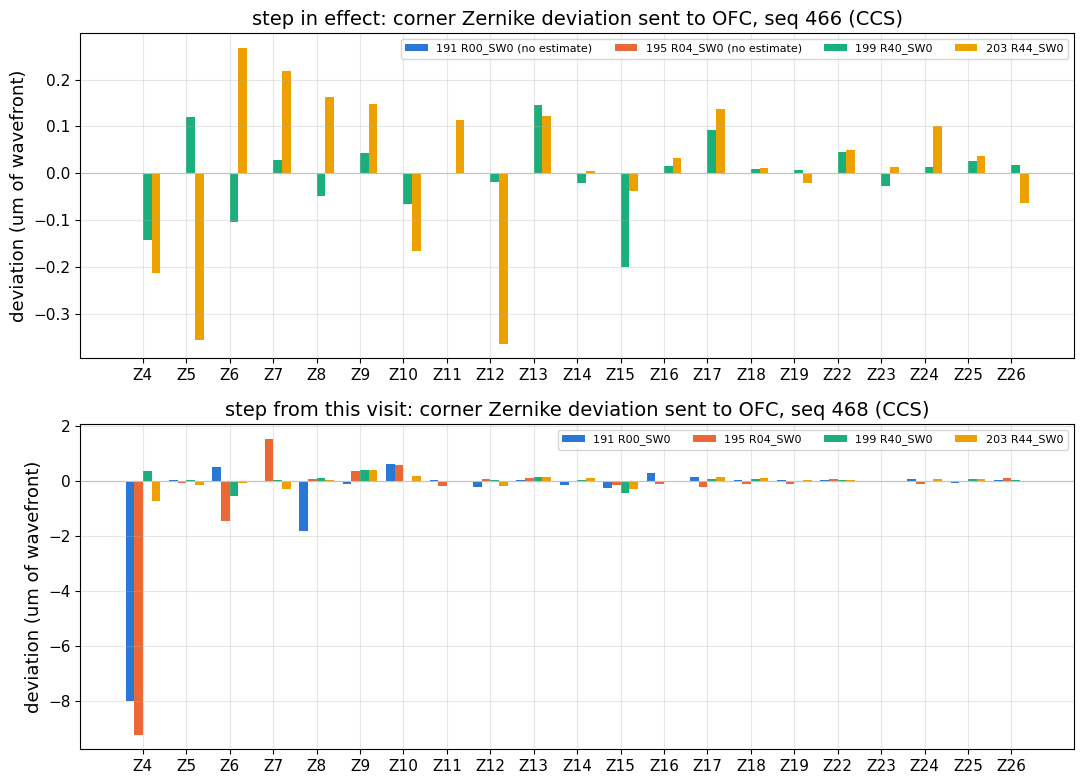

/lscratch/roodman/ipykernel_2982241/2006183485.py:61: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


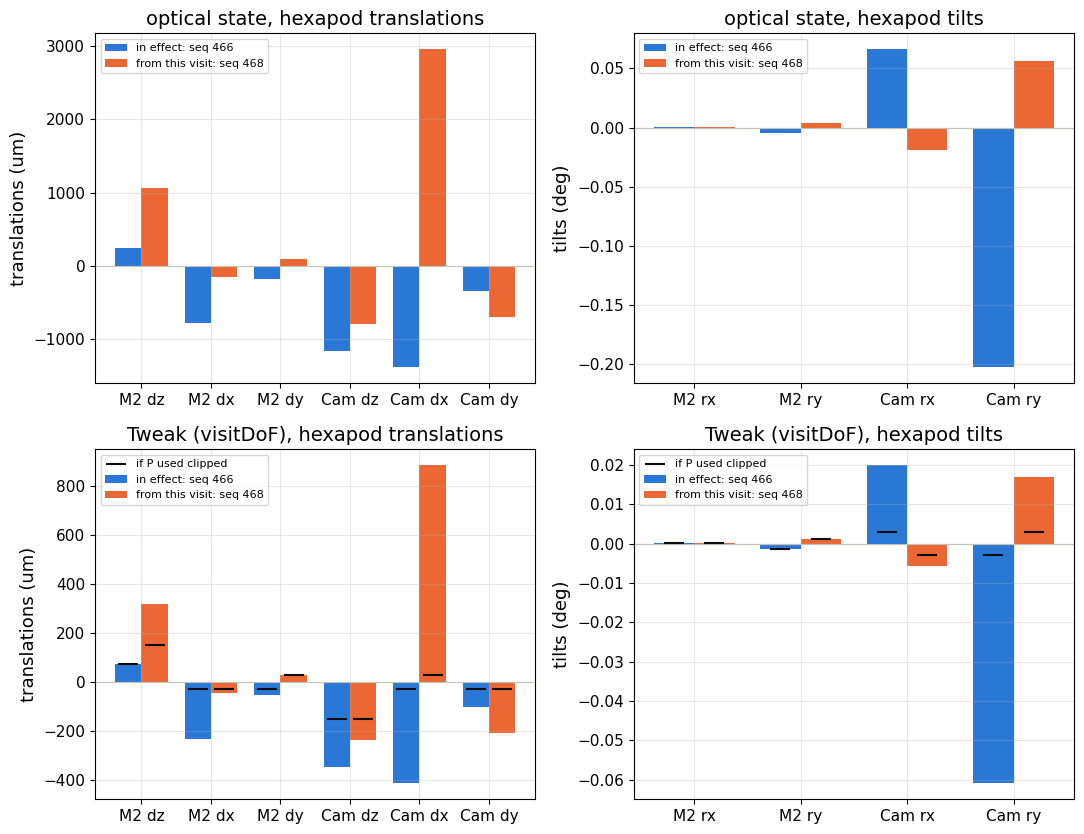

/lscratch/roodman/ipykernel_2982241/2006183485.py:76: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


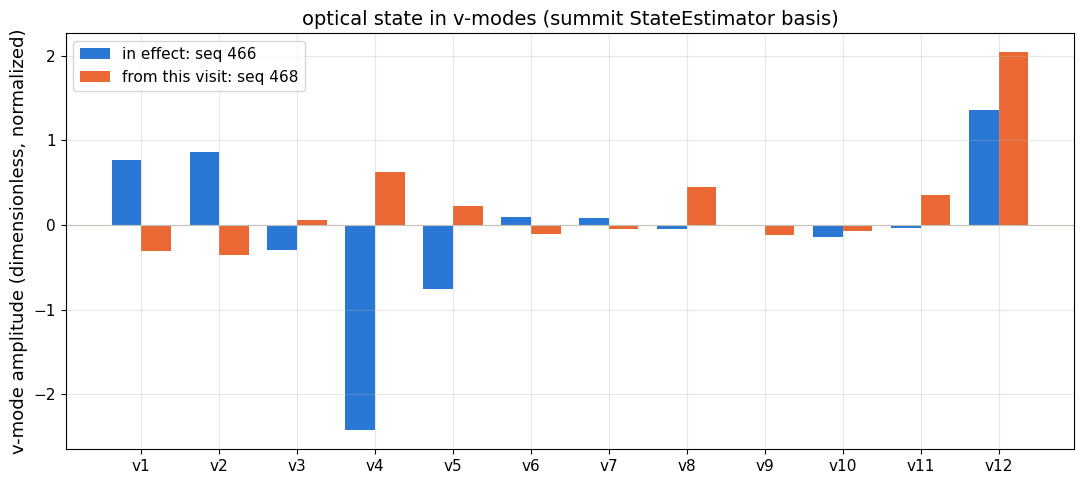

/lscratch/roodman/ipykernel_2982241/2006183485.py:93: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


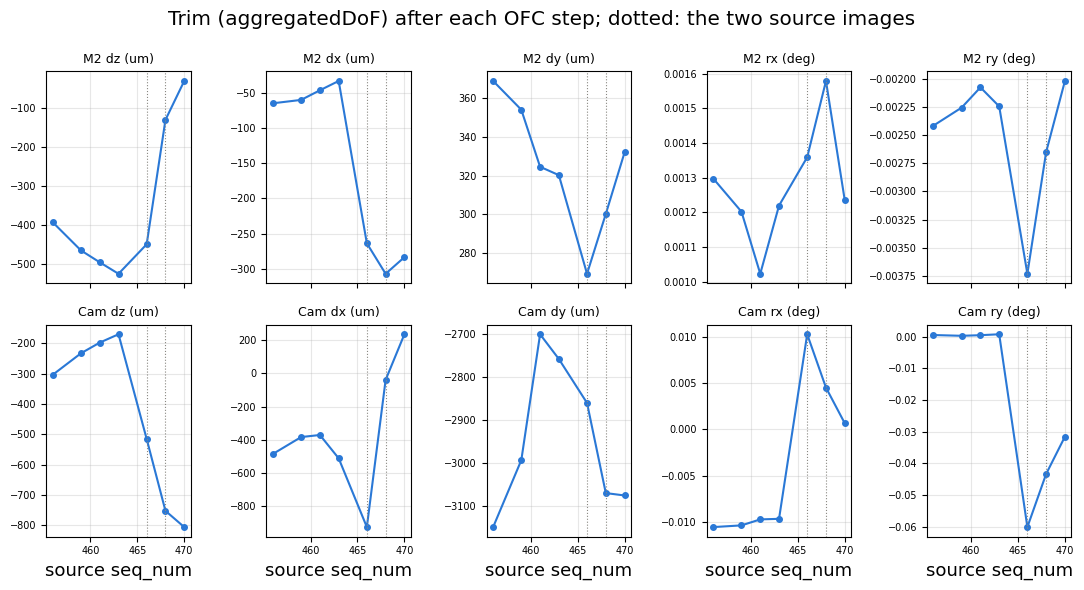

/sdf/group/rubin/u/roodman/LSST/rubin-work/studies/aos/aos_byvisit/20261109_visit_20261108_00468/aos_byvisit_20261108_00468.pdf


In [12]:
CORNER_COLORS = {191: "#2a78d6", 195: "#eb6834", 199: "#1baf7a", 203: "#eda100"}
STEP_COLORS = ["#2a78d6", "#eb6834"]
pdf_path = run.path / f"aos_byvisit_{DAY_OBS}_{SEQ_NUM:05d}.pdf"


def page_summary():
    fig = plt.figure(figsize=(11, 8.5))
    fig.text(0.04, 0.96, f"MTAOS steps for {DAY_OBS} seq {SEQ_NUM}", fontsize=16, va="top")
    lines = [f"versions: {versions.get('subsystems', '')}; config {versions.get('config_version', '')}", ""]
    for n, a in cases.items():
        s, w = a["step"], a["wep"]
        cam = a["table"].loc[["Cam dz", "Cam dx", "Cam dy"], "tweak (EFD visitDoF)"].round(1).to_dict()
        lines += [f"step {n}: source seq {a['src']} -> applied to seq {s.applied_to_seq}",
                  f"   finite corners {a['rep']['corners_used']}; MTAOS claimed {w['measurements_claimed']} "
                  f"measurements, tables {w['tables_found']}/{w['tables_total']}",
                  f"   camera hexapod tweak (um): {cam}",
                  f"   reproduction max rel. error of PID error {a['repro_rel']:.1e} (dimensionless)", ""]
    fig.text(0.04, 0.88, "\n".join(lines), fontsize=10, va="top", family="monospace")
    return fig


def page_zernikes():
    fig, axes = plt.subplots(len(cases), 1, figsize=(11, 4 * len(cases)), squeeze=False)
    x = np.arange(len(bv.ZN21))
    for ax, (n, a) in zip(axes[:, 0], cases.items()):
        for k, det in enumerate(bv.CORNER_IDS):
            vals = a["wfe"].loc[det].to_numpy() if det in a["wfe"].index else np.full(len(x), np.nan)
            lab = f"{det} {bv.CORNER_NAMES[det]}" + (" (no estimate)" if np.isnan(vals).all() else "")
            ax.bar(x + (k - 1.5) * 0.2, np.nan_to_num(vals), 0.2, color=CORNER_COLORS[det], label=lab)
        ax.axhline(0, color="#c3c2b7", lw=0.8)
        ax.set_xticks(x, [f"Z{j}" for j in bv.ZN21])
        ax.set_ylabel("deviation (um of wavefront)")
        ax.set_title(f"step {n}: corner Zernike deviation sent to OFC, seq {a['src']} (CCS)")
        ax.legend(fontsize=8, ncol=4)
    fig.tight_layout()
    return fig


def page_hexapods():
    fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
    groups = [("translations (um)", [d for d in HEX if d.endswith(("dz", "dx", "dy"))]),
              ("tilts (deg)", [d for d in HEX if d.endswith(("rx", "ry"))])]
    for row, (col_name, title) in enumerate([("state (log, -error)", "optical state"),
                                             ("tweak (EFD visitDoF)", "Tweak (visitDoF)")]):
        for c, (glab, dofs) in enumerate(groups):
            ax = axes[row, c]
            x = np.arange(len(dofs))
            for k, (n, a) in enumerate(cases.items()):
                ax.bar(x + (k - 0.5) * 0.38, a["table"].loc[dofs, col_name], 0.38,
                       color=STEP_COLORS[k], label=f"{n}: seq {a['src']}")
            if row == 1:
                for k, (n, a) in enumerate(cases.items()):
                    ax.scatter(x + (k - 0.5) * 0.38, a["table"].loc[dofs, "tweak if P used clipped"],
                               marker="_", s=200, color="#0b0b0b", zorder=3,
                               label="if P used clipped" if k == 0 else None)
            ax.axhline(0, color="#c3c2b7", lw=0.8)
            ax.set_xticks(x, dofs)
            ax.set_ylabel(glab)
            ax.set_title(f"{title}, hexapod {glab.split()[0]}")
            ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


def page_vmodes():
    fig, ax = plt.subplots(figsize=(11, 5))
    x = np.arange(1, bv.N_VMODES + 1)
    for k, (n, a) in enumerate(cases.items()):
        ax.bar(x + (k - 0.5) * 0.38, a["rep"]["vmodes"][:bv.N_VMODES], 0.38,
               color=STEP_COLORS[k], label=f"{n}: seq {a['src']}")
    ax.axhline(0, color="#c3c2b7", lw=0.8)
    ax.set_xticks(x, [f"v{i}" for i in x])
    ax.set_ylabel("v-mode amplitude (dimensionless, normalized)")
    ax.set_title("optical state in v-modes (summit StateEstimator basis)")
    ax.legend()
    fig.tight_layout()
    return fig


def page_trim():
    fig, axes = plt.subplots(2, 5, figsize=(11, 6), sharex=True)
    seqs = steps.index.to_numpy()
    for ax, d in zip(axes.ravel(), HEX):
        i = bv.DOF_NAMES.index(d)
        ax.plot(seqs, [steps.loc[s].trim[i] for s in seqs], "-o", ms=4, lw=1.5, color="#2a78d6")
        for n, a in cases.items():
            ax.axvline(a["src"], color="#898781", lw=0.8, ls=":")
        ax.set_title(f"{d} ({bv.DOF_UNITS[i]})", fontsize=9)
        ax.tick_params(labelsize=7)
    for ax in axes[1]:
        ax.set_xlabel("source seq_num")
    fig.suptitle("Trim (aggregatedDoF) after each OFC step; dotted: the two source images")
    fig.tight_layout()
    return fig


with PdfPages(pdf_path) as pdf:
    for make in (page_summary, page_zernikes, page_hexapods, page_vmodes, page_trim):
        fig = make()
        pdf.savefig(fig)
        plt.show()
print(pdf_path)